In [1]:
# Exercice 3 : Apprentissage d'un CNN sur le dataset MNIST
# Objectif apprendre à classifier les images de chiffres manuscrits (0 à 9) à l'aide d'un réseau de neurones convolutif (CNN)

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import pandas as pd

I0000 00:00:1791799342.074878  722973 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791799342.377546  722973 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791799343.924991  722973 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
# 2. Chargement du dataset MNIST 
# Il contient 60 000 images d'entraînement et 10 000 images de test de chiffres écrits à la main (taille 28x28 pixels).
(X_train_raw, y_train), (X_test_raw, y_test) = datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


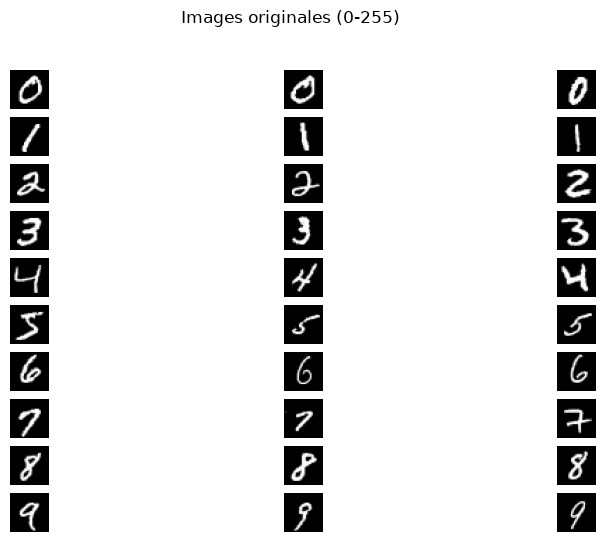

In [3]:
# 3. Visualisation des 3 premiers exemples pour chacun des 10 chiffres (de 0 à 9)
plt.figure(figsize=(10, 6))
for digit in range(10):
    # Recherche des indices correspondant au chiffre actuel dans le jeu d'entraînement
    idx = np.where(y_train == digit)[0][:3]
    for i, j in enumerate(idx):
        plt.subplot(10, 3, digit * 3 + i + 1)
        plt.imshow(X_train_raw[j], cmap='gray')  # Affichage de l'image en nuances de gris[cite: 8]
        plt.axis('off')
plt.suptitle("Images originales (0-255)")
plt.show()

In [6]:
# Normalisation : les pixels passent de 0-255 à 0-1.

# 1. Conversion du type de données en nombres décimaux (float32) et division par 255.0.
# Les images brutes MNIST sont composées de pixels allant de 0 (noir) à 255 (blanc). 
# Diviser par 255.0 permet de ramener toutes ces valeurs dans un intervalle compris entre 0.0 et 1.0, 
# ce qui stabilise et accélère considérablement l'apprentissage du réseau de neurones convolutif (CNN).
X_train = X_train_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

In [7]:
# Ajout du canal : (N, 28, 28) devient (N, 28, 28, 1).

# 2. Ajout d'une dimension supplémentaire à la fin du tableau (axe -1) pour spécifier le nombre de canaux de couleur.
# Le jeu de données initial fournit des images en 2D de forme (N, 28, 28). 
# Or, un CNN s'attend par défaut à un format en 3D par image (Hauteur, Largeur, Canaux). 
# Comme il s'agit d'images en nuances de gris, il n'y a qu'un seul canal (noir et blanc), 
# d'où la valeur 1 qui transforme la forme en (N, 28, 28, 1).
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

# 3. Affichage des formes (shapes) finales des matrices pour vérifier que les dimensions sont conformes aux attentes du CNN.
print("Formes finales :", X_train.shape, X_test.shape)

Formes finales : (60000, 28, 28, 1) (10000, 28, 28, 1)


In [9]:
import os
# Désactive l'utilisation du GPU pour forcer TensorFlow à tourner sur le CPU
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

In [10]:
# 1. Construction de l'architecture du CNN
model = models.Sequential([
    # Couche d'entrée : spécifie que le modèle reçoit des images de 28x28 pixels avec 1 canal (niveaux de gris).
    Input(shape=(28, 28, 1)),
    
    # Bloc de Convolution 1 : 32 filtres (ou noyaux) de taille (3,3) avec une fonction d'activation 'relu'.
    # Permet d'extraire des caractéristiques visuelles de bas niveau (bords, lignes, contours).
    layers.Conv2D(32, (3, 3), activation='relu'),
    
    # Couche de MaxPooling 1 : réduit de moitié les dimensions spatiales (de 28x28 à 14x14) 
    # en conservant les valeurs maximales, ce qui diminue le nombre de paramètres et rend le calcul plus robuste.
    layers.MaxPooling2D((2, 2)),
    
    # Bloc de Convolution 2 : 64 filtres de taille (3,3) avec 'relu'.
    # Permet de capturer des motifs un peu plus complexes.
    layers.Conv2D(64, (3, 3), activation='relu'),
    
    # Couche de MaxPooling 2 : réduit à nouveau les dimensions spatiales (de 14x14 à 7x7).
    layers.MaxPooling2D((2, 2)),
    
    # Bloc de Convolution 3 : 64 filtres de taille (3,3) avec 'relu'.
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Couche Flatten : aplatit la carte de caractéristiques 2D/3D en un grand vecteur 1D 
    # pour pouvoir le connecter à des couches denses classiques (Fully Connected).
    layers.Flatten(),
    
    # Couche Dense (cachée) : 128 neurones avec 'relu' pour effectuer le raisonnement logique à partir des motifs extraits.
    layers.Dense(128, activation='relu'),
    
    # Couche Dropout (0.5) : désactive aléatoirement 50% des connexions pendant l'entraînement 
    # afin de lutter efficacement contre le surapprentissage (overfitting).
    layers.Dropout(0.5),
    
    # Couche de Sortie : 128 neurones réduits à 10 (un pour chaque chiffre de 0 à 9) 
    # avec la fonction d'activation 'softmax' qui convertit les scores bruts en probabilités.
    layers.Dense(10, activation='softmax')
])

In [11]:
# 2. Compilation du modèle
model.compile(
    optimizer='adam',                               # L'optimiseur 'adam' ajuste automatiquement les poids pour minimiser l'erreur.
    loss='sparse_categorical_crossentropy',         # La fonction de perte adaptée lorsque les étiquettes (y) sont des entiers bruts (0 à 9) et non des vecteurs One-Hot.
    metrics=['accuracy']                            # Suivi de la précision (pourcentage de bonnes prédictions) tout au long de l'apprentissage.
)

In [12]:
# 3. Affichage du résumé (summary) détaillant chaque couche, la forme des tenseurs de sortie et le nombre total de paramètres à entraîner.
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# La validation est prélevée dans le train (validation_split) : le jeu de test reste inconnu jusqu'à l'évaluation finale.

# 1. Entraînement du CNN
# On lance l'apprentissage sur 5 époques avec des lots de 64 images, 
# en réservant 10% des données d'entraînement pour valider les performances à chaque époque.
history = model.fit(
    X_train, y_train, 
    epochs=5, 
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5


W0000 00:00:1791800166.806968  722973 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.9162 - loss: 0.2728 - val_accuracy: 0.9842 - val_loss: 0.0525
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 21s 25ms/step - accuracy: 0.9788 - loss: 0.0745 - val_accuracy: 0.9867 - val_loss: 0.0405
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.9838 - loss: 0.0553 - val_accuracy: 0.9888 - val_loss: 0.0358
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9872 - loss: 0.0441 - val_accuracy: 0.9885 - val_loss: 0.0357
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.9899 - loss: 0.0362 - val_accuracy: 0.9885 - val_loss: 0.0382


In [15]:
# 2. Évaluation du modèle sur le jeu de test (données totalement inédites)
# 'verbose=2' permet d'afficher un résumé épuré des résultats de l'évaluation.
loss, acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test: {acc*100:.2f}%")

313/313 - 1s - 3ms/step - accuracy: 0.9902 - loss: 0.0298

Précision sur le test: 99.02%


In [16]:
# 3. Génération des prédictions sur tout le jeu de test
# 'np.argmax' convertit les probabilités de sortie de la couche softmax en classes finales (chiffres de 0 à 9).
y_pred = np.argmax(model.predict(X_test), axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step


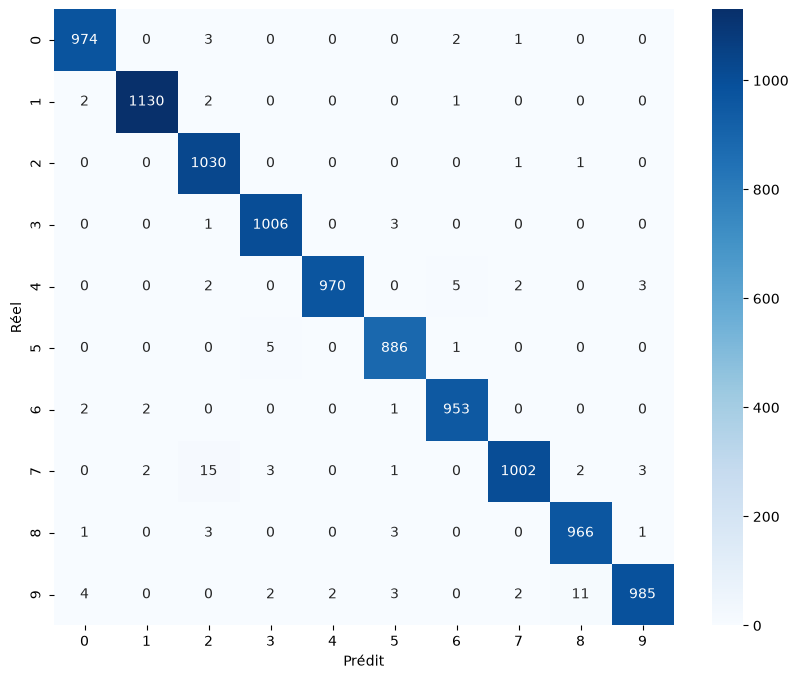

In [17]:
# 4. Création et affichage de la matrice de confusion (sous forme de heatmap Seaborn)
# Permet de voir visuellement si le modèle confond certains chiffres (ex: confondre un 4 avec un 9).
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()

In [18]:
# 5. Affichage du rapport de classification complet 
# Fournit les métriques de précision (precision), de rappel (recall) et de score F1 pour chaque chiffre de 0 à 9.
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       1.00      1.00      1.00      1135
           2       0.98      1.00      0.99      1032
           3       0.99      1.00      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.97      0.98      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



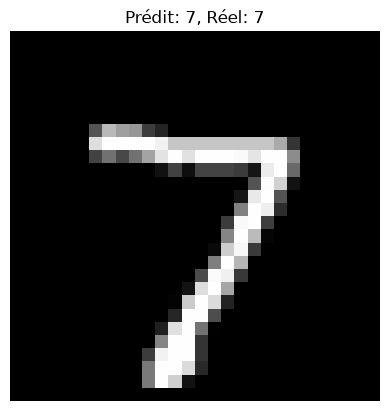

In [19]:
# 1. Affichage de la prédiction pour le tout premier exemple du jeu de test (X_test[0])

# Affiche l'image du chiffre sous forme de matrice 28x28 pixels en nuances de gris.
plt.imshow(X_test[0].reshape(28, 28), cmap="gray")

# Ajoute un titre dynamique au-dessus de l'image indiquant 
# ce que le modèle a prédit (y_pred[0]) et ce qu'était le vrai chiffre attendu (y_test[0]).
plt.title(f"Prédit: {y_pred[0]}, Réel: {y_test[0]}")

# Désactive les axes graphiques (graduations) pour une meilleure lisibilité.
plt.axis('off')
plt.show()

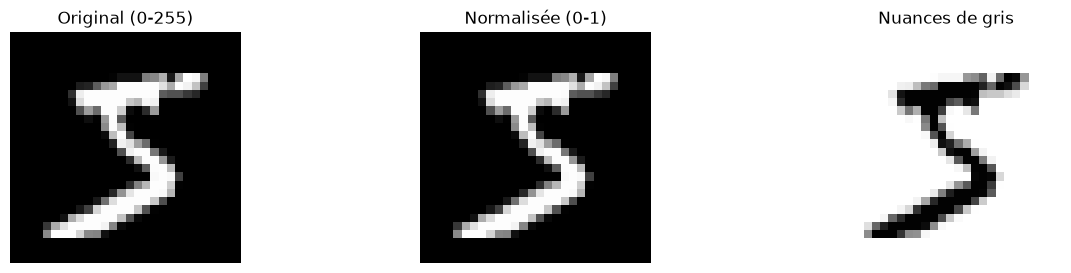

In [20]:
# 2. Comparaison visuelle de l'impact de la normalisation sur un chiffre (ici le chiffre 5)

# Sélectionne la toute première occurrence du chiffre 5 dans les données d'entraînement brutes (échelle 0-255).
img = X_train_raw[y_train == 5][0]  # image brute, valeurs de 0 à 255

# Crée une figure globale de taille 15x3 pour aligner 3 graphiques côte à côte.
plt.figure(figsize=(15, 3))

# --- Premier sous-graphique : L'image originale ---
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original (0-255)")
plt.axis('off')

# --- Second sous-graphique : L'image normalisée (échelle 0 à 1) ---
img_norm = img.astype("float32") / 255.0  # même image, valeurs de 0 à 1
plt.subplot(1, 3, 2)
plt.imshow(img_norm, cmap='gray')
plt.title("Normalisée (0-1)")
plt.axis('off')

# --- Troisième sous-graphique : L'image normalisée avec une autre palette de couleurs ('Greys') ---
plt.subplot(1, 3, 3)
plt.imshow(img_norm, cmap='Greys')
plt.title("Nuances de gris")
plt.axis('off')

# Affiche la figure complète contenant les 3 visualisations côte à côte.
plt.show()

In [1]:
# 2eme Etude
# Expliquez le code réalisé dans ce notebook, en précisant le role de chaque étape (prétraitement, architecture du CNN, 
# entraînement, évaluation).

"""
Synthèse du Notebook : Pipeline de Classification d'Images par CNN (MNIST)

1. Prétraitement des données (Data Preprocessing)

Le prétraitement a pour objectif de préparer les images brutes pour qu'elles soient exploitables de manière optimale 
par le réseau de neurones :
- Normalisation des pixels : Les valeurs des pixels des images de base, comprises entre $0$ et $255$ (niveaux de gris), 
sont converties en nombres décimaux et divisées par $255.0$.
Cela permet de ramener l'ensemble des données dans une échelle homogène $[0, 1]$, stabilisant ainsi la descente de gradient et 
accélérant la convergence lors de l'apprentissage.
- Ajout de la dimension du canal : Les matrices d'images 2D initiales de forme $(N, 28, 28)$ sont redimensionnées en
tenseurs 3D de forme $(N, 28, 28, 1)$ à l'aide de np.expand_dims.
Cette étape explicite la présence d'un canal unique (niveaux de gris), indispensable pour que les couches de convolution 
puissent traiter les images.

2. Architecture du CNN (Réseau de Neurones Convolutif)
L'architecture séquentielle du modèle s'articule autour de deux grands blocs fonctionnels :

- Extraction des caractéristiques (Feature Extraction) : Composée de couches de convolutions successives 
(Conv2D avec des filtres de $3 \times 3$ et une activation relu) et de sous-échantillonnage (MaxPooling2D).
Ces couches permettent d'extraire automatiquement les motifs visuels de bas et haut niveau (bords, lignes, boucles des chiffres) 
tout en réduisant la dimension spatiale. 

- Classification (Fully Connected) : Les cartes de caractéristiques 2D sont aplaties via une couche Flatten().
Un réseau dense classique de $128$ neurones (Dense avec relu) analyse ces motifs, secondé par une couche de régularisation Dropout(0.5) 
qui désactive aléatoirement 50 % des connexions pour éviter le surapprentissage (overfitting).
Enfin, la couche de sortie (Dense de 10 neurones avec softmax) fournit les probabilités d'appartenance pour chaque chiffre de $0$ à $9$.     

3. Entraînement du modèle (Training)

- Le modèle est compilé avec l'optimiseur adam, la fonction de perte sparse_categorical_crossentropy 
(adaptée aux étiquettes sous forme d'entiers bruts) et la métrique de suivi accuracy.

- L'apprentissage s'effectue via la méthode fit sur plusieurs époques, en découpant le jeu d'entraînement en lots (batches).
Un sous-ensemble de validation (validation_split=0.1) est mis de côté à chaque époque pour surveiller la capacité de généralisation 
du modèle en temps réel.

4. Évaluation et Analyse des performances (Evaluation)

- Évaluation globale : Le modèle est testé sur le jeu de test (X_test, y_test) — d
es données totalement inédites — pour mesurer sa précision finale (Test Accuracy).
- Analyse fine : L'utilisation d'une matrice de confusion (visualisée via une heatmap Seaborn) et d'un rapport 
de classification (classification_report) permet d'identifier précisément les performances classe par classe, 
mettant en lumière d'éventuelles confusions entre certains chiffres manuscrits similaires.  
"""
